# EN4554 – Assignment 2: Convolutional Neural Networks

**Name:** *Pirathishanth*  
**Index number:** *220480P*  
**GitHub  :** https://github.com/pirathi2002/EN4554-Assignment-2-Convolutional-Neural-Networks

---

### Contents
| Part | Topic | Rough run time on a Colab T4 |
|---|---|---|
| Setup | Data, utilities | 1 min |
| Task 1 | Backpropagation from scratch (Linear / ReLU / softmax-CE), gradient checks, MLP training, vanishing gradients | ~5 min |
| Task 2 | Own SGD-momentum and Adam, behaviour on an ill-conditioned quadratic, optimiser / learning-rate sweep on a CNN | ~15 min |
| Task 3 | Regularisation study on 5k images; plain vs residual networks of depth 8 / 20 / 56 | ~60–90 min |
| Task 4 (optional) | Best CNN with ≤ 500k parameters and ≤ 20 epochs, ablation, one-shot test evaluation | ~30 min |

### Use of AI tools (required acknowledgement)
I used Claude (Anthropic) to help generate the initial code structure and the interpretation drafts of this notebook. I ran all the experiments myself on a Colab T4, checked the interpretations against my own results, and I understand the code.

In [22]:
import os, time, math, random, json, copy
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

QUICK = False          # True -> tiny subsets + 1-2 epochs: a smoke test of the whole notebook
QUICK_N = (3000, 600)  # (#train, #val) used in QUICK mode
SEED = 42

def E(full, quick=1):
    """Number of epochs: `full` normally, `quick` in QUICK mode."""
    return quick if QUICK else full

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('torch', torch.__version__, '| device:', device, '| QUICK =', QUICK)

torch 2.11.0+cu130 | device: cuda | QUICK = False


## 0. Data: CIFAR-10, 45k / 5k split, per-channel normalisation

* The 50,000 official training images are split (fixed seed) into **45,000 train / 5,000 validation**.
* Each colour channel is normalised with the **mean / std of the 45k training images only** (no leakage from validation or test).
* The official 10,000-image **test set is not loaded here**; it is touched exactly once, at the very end of Task 4.
* The whole dataset is kept as tensors on the GPU, so training loops are fast and augmentation is done on the GPU as well.

train (45000, 3, 32, 32) | val (5000, 3, 32, 32)
channel mean [0.4917 0.4823 0.4467] | std [0.2471 0.2435 0.2616]
train class counts [4512, 4488, 4468, 4529, 4529, 4486, 4493, 4500, 4496, 4499]
val   class counts [488, 512, 532, 471, 471, 514, 507, 500, 504, 501]


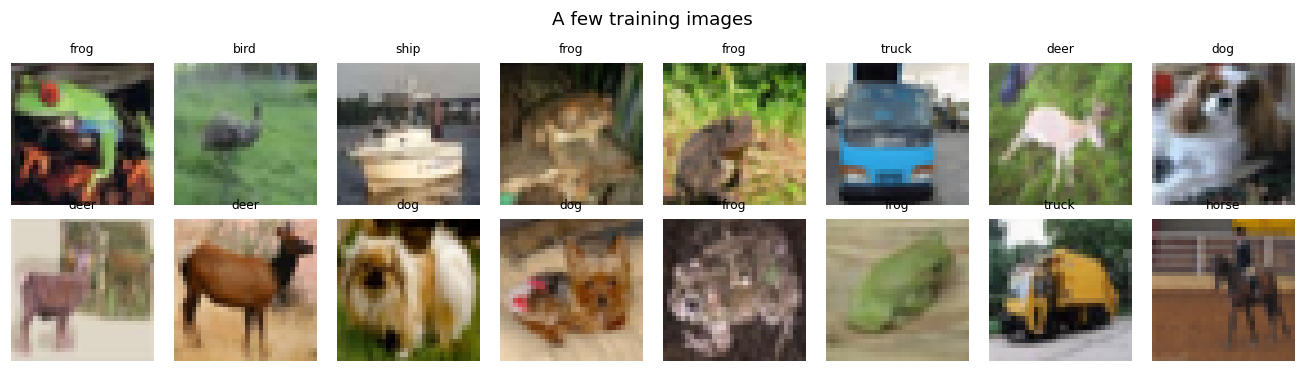

In [23]:
tv_train = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
CLASSES = tv_train.classes
X_u8 = torch.from_numpy(tv_train.data).permute(0, 3, 1, 2).contiguous()      # (50000,3,32,32) uint8
y_all = torch.tensor(tv_train.targets)

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(X_u8), generator=g)
tr_idx, va_idx = perm[:45000], perm[45000:]
if QUICK:
    tr_idx, va_idx = tr_idx[:QUICK_N[0]], va_idx[:QUICK_N[1]]

Xtr_raw = X_u8[tr_idx].float().div(255)
mean = Xtr_raw.mean((0, 2, 3), keepdim=True)          # per-channel statistics of the TRAINING split only
std  = Xtr_raw.std((0, 2, 3), keepdim=True)
Xtr = ((Xtr_raw - mean) / std).to(device); ytr = y_all[tr_idx].to(device)
Xva = ((X_u8[va_idx].float().div(255) - mean) / std).to(device); yva = y_all[va_idx].to(device)
del Xtr_raw
mean_d, std_d = mean.to(device), std.to(device)
def denorm(x): return (x * std_d + mean_d).clamp(0, 1)

print('train', tuple(Xtr.shape), '| val', tuple(Xva.shape))
print('channel mean', mean.flatten().numpy().round(4), '| std', std.flatten().numpy().round(4))
print('train class counts', torch.bincount(ytr.cpu(), minlength=10).tolist())
print('val   class counts', torch.bincount(yva.cpu(), minlength=10).tolist())

fig, ax = plt.subplots(2, 8, figsize=(12, 3.4))
for i, a in enumerate(ax.flat):
    a.imshow(denorm(Xtr[i:i+1])[0].permute(1, 2, 0).cpu()); a.set_title(CLASSES[ytr[i]], fontsize=8); a.axis('off')
plt.suptitle('A few training images'); plt.tight_layout(); plt.show()

## Shared utilities
`evaluate` (loss / accuracy in eval mode) and `train_model` (a generic training loop that supports GPU augmentation, mixup, label smoothing, a per-step LR scheduler, and records per-epoch curves). Everything later reuses these.

In [24]:
def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    """Mean cross-entropy and accuracy of `model` (eval mode) on (X, y)."""
    was_training = model.training; model.eval()
    tot, ok = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(X[i:i+bs])
        tot += F.cross_entropy(out, y[i:i+bs], reduction='sum').item()
        ok += (out.argmax(1) == y[i:i+bs]).sum().item()
    model.train(was_training)
    return tot / len(X), ok / len(X)

def warmup_cosine(opt, total_steps, warmup_steps=0):
    """Linear warm-up followed by cosine decay to 0; call .step() once per iteration."""
    def f(s):
        if s < warmup_steps: return (s + 1) / warmup_steps
        pr = (s - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * pr))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def train_model(model, opt, epochs, Xt, yt, Xv, yv, bs=128, augment=None, mixup_alpha=0.0,
                scheduler=None, label_smoothing=0.0, eval_train=False, tag='', log_every=None):
    """Generic training loop. Returns a dict of per-epoch curves.
    train_loss : running mean of the (possibly augmented / mixed) minibatch loss during the epoch
    train_acc  : accuracy on the CLEAN training set in eval mode if eval_train else running accuracy
    val_*      : clean validation loss / accuracy in eval mode
    """
    model.to(device)
    hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'time']}
    hist['diverged'] = False
    n = len(Xt); nb = n // bs                       # drop the last incomplete batch (a new shuffle each epoch)
    log_every = log_every or max(1, epochs // 5)
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, device=Xt.device)
        run_loss = torch.zeros((), device=Xt.device); run_ok = torch.zeros((), device=Xt.device)
        for k in range(nb):
            b = perm[k*bs:(k+1)*bs]
            xb, yb = Xt[b], yt[b]
            if augment is not None: xb = augment(xb)
            if mixup_alpha > 0:                     # mixup: convex combination of two minibatches / label sets
                lam = float(np.random.beta(mixup_alpha, mixup_alpha))
                p = torch.randperm(len(xb), device=xb.device)
                out = model(lam * xb + (1 - lam) * xb[p])
                loss = lam * F.cross_entropy(out, yb, label_smoothing=label_smoothing) \
                     + (1 - lam) * F.cross_entropy(out, yb[p], label_smoothing=label_smoothing)
            else:
                out = model(xb)
                loss = F.cross_entropy(out, yb, label_smoothing=label_smoothing)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            if scheduler is not None: scheduler.step()
            run_loss += loss.detach() * len(b); run_ok += (out.argmax(1) == yb).sum()
        tl = run_loss.item() / (nb * bs)
        ta = evaluate(model, Xt, yt)[1] if eval_train else run_ok.item() / (nb * bs)
        vl, va = evaluate(model, Xv, yv)
        for k_, v_ in zip(['train_loss', 'train_acc', 'val_loss', 'val_acc', 'time'], [tl, ta, vl, va, time.time() - t0]):
            hist[k_].append(v_)
        if (ep + 1) % log_every == 0 or ep == 0 or ep == epochs - 1:
            print(f'[{tag}] ep {ep+1:3d}/{epochs} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:5.0f}s')
        if not math.isfinite(tl):
            hist['diverged'] = True; print(f'[{tag}] diverged (loss = {tl}) - stopping early'); break
    return hist

# Task 4 (optional) – The best CNN with ≤ 500k parameters and ≤ 20 epochs

**Design.** A CIFAR ResNet of depth 20 (n = 3) widened to channels **20 / 40 / 80** → ≈0.42M parameters (checked by an `assert` below), because Task 3(b) showed that residual connections make such networks easy to train. Training recipe (20 epochs, batch 128): SGD + Nesterov momentum 0.9, **one-cycle** learning-rate schedule (peak 0.2), weight decay 5e-4, **label smoothing** 0.1, **flip + crop + cutout (8×8)** augmentation. All design decisions are made on the **validation** split; the test set is not loaded until the very last cell.

**Ablation.** Starting from the full recipe, one design choice at a time is removed / replaced (same seed, same epochs):
shortcut (plain network), augmentation, weight decay, label smoothing, and the optimiser (AdamW).

In [40]:
EPOCHS_4, BS_4, WIDTHS_4, MAX_PARAMS = E(20, 2), 128, (20, 40, 80), 500_000
assert EPOCHS_4 <= 20

BASE_CFG = dict(shortcut=True, aug='flipcrop+cutout', wd=5e-4, opt='sgd', label_smoothing=0.1)
AUGS = {'none': None, 'flipcrop': random_crop_flip, 'flipcrop+cutout': lambda x: cutout(random_crop_flip(x), 8)}

def run_t4(cfg, tag):
    set_seed()
    model = CifarNet(20, residual=cfg['shortcut'], widths=WIDTHS_4).to(device)
    assert count_params(model) <= MAX_PARAMS, 'too many parameters'
    if cfg['opt'] == 'sgd':
        opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=cfg['wd']); max_lr = 0.2
    else:   # AdamW: decoupled weight decay (coupled L2 interacts badly with Adam's per-parameter scaling)
        opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=cfg['wd'] * 100); max_lr = 4e-3
    steps = EPOCHS_4 * (len(Xtr) // BS_4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=max_lr, total_steps=steps, pct_start=0.25, cycle_momentum=False)
    h = train_model(model, opt, EPOCHS_4, Xtr, ytr, Xva, yva, bs=BS_4, augment=AUGS[cfg['aug']], scheduler=sched,
                    label_smoothing=cfg['label_smoothing'], tag=tag, log_every=5)
    return model, h

ABLATION = {
    'full recipe (final model)':      {},
    'no shortcut (plain network)':    dict(shortcut=False),
    'no augmentation':                dict(aug='none'),
    'flip+crop only (no cutout)':     dict(aug='flipcrop'),
    'no weight decay':                dict(wd=0.0),
    'no label smoothing':             dict(label_smoothing=0.0),
    'AdamW instead of SGD':           dict(opt='adamw'),
}
print('parameters of the final architecture:', f'{count_params(CifarNet(20, True, WIDTHS_4)):,}', f'(limit {MAX_PARAMS:,})')
abl, final_model = {}, None
for name, delta in ABLATION.items():
    model, h = run_t4({**BASE_CFG, **delta}, name)
    abl[name] = h
    if name.startswith('full'): final_model = model

parameters of the final architecture: 420,670 (limit 500,000)
[full recipe (final model)] ep   1/20 | train loss 1.803 acc 0.390 | val loss 1.485 acc 0.460 |    22s
[full recipe (final model)] ep   5/20 | train loss 1.142 acc 0.723 | val loss 0.980 acc 0.673 |   110s
[full recipe (final model)] ep  10/20 | train loss 1.001 acc 0.785 | val loss 0.675 acc 0.779 |   221s
[full recipe (final model)] ep  15/20 | train loss 0.853 acc 0.853 | val loss 0.484 acc 0.857 |   331s
[full recipe (final model)] ep  20/20 | train loss 0.702 acc 0.920 | val loss 0.340 acc 0.900 |   442s
[no shortcut (plain network)] ep   1/20 | train loss 1.930 acc 0.312 | val loss 1.655 acc 0.405 |    22s
[no shortcut (plain network)] ep   5/20 | train loss 1.234 acc 0.675 | val loss 1.297 acc 0.561 |   108s
[no shortcut (plain network)] ep  10/20 | train loss 1.094 acc 0.742 | val loss 0.945 acc 0.677 |   215s
[no shortcut (plain network)] ep  15/20 | train loss 0.931 acc 0.812 | val loss 0.610 acc 0.809 |   323s
[no

configuration                    final val acc  delta vs full  final train loss
full recipe (final model)               0.9000         +0.00%            0.7024
no shortcut (plain network)             0.8824         -1.76%            0.7549
no augmentation                         0.8760         -2.40%            0.5216
flip+crop only (no cutout)              0.9054         +0.54%            0.6603
no weight decay                         0.8918         -0.82%            0.7233
no label smoothing                      0.9066         +0.66%            0.2407
AdamW instead of SGD                    0.9002         +0.02%            0.6980


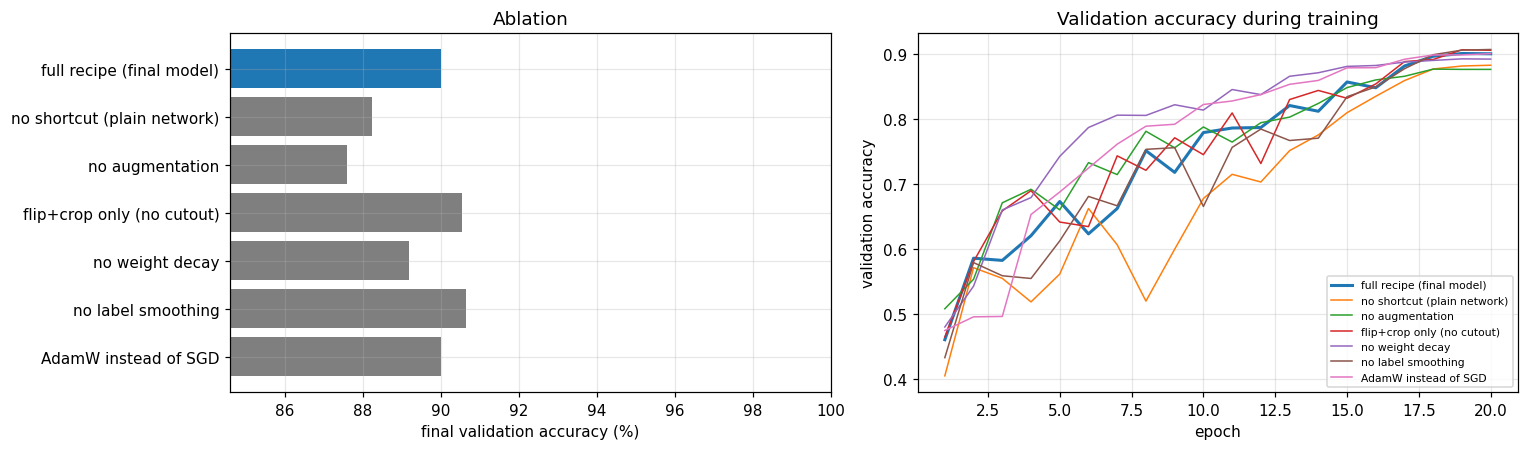

In [41]:
ref = abl['full recipe (final model)']['val_acc'][-1]
print(f"{'configuration':32s}{'final val acc':>14s}{'delta vs full':>15s}{'final train loss':>18s}")
for name, h in abl.items():
    print(f"{name:32s}{h['val_acc'][-1]:14.4f}{100*(h['val_acc'][-1]-ref):+14.2f}%{h['train_loss'][-1]:18.4f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
names = list(abl)
vals = [abl[n]['val_acc'][-1] * 100 for n in names]
ax[0].barh(names[::-1], vals[::-1], color=['C0' if n.startswith('full') else 'C7' for n in names[::-1]])
ax[0].set_xlim(max(0, min(vals) - 3), 100); ax[0].set_xlabel('final validation accuracy (%)'); ax[0].set_title('Ablation')
for n in names:
    ax[1].plot(range(1, len(abl[n]['val_acc']) + 1), abl[n]['val_acc'], label=n, lw=2 if n.startswith('full') else 1)
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('validation accuracy'); ax[1].set_title('Validation accuracy during training'); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Interpretation (4, ablation).** The full recipe reaches 90.00% validation accuracy. Removing **augmentation** causes the largest drop (−2.40 points): the network then reaches 99.9% training accuracy but only 87.6% on validation, so it overfits strongly. Removing the **shortcut** costs −1.76 points (88.24%), because the plain network is harder to optimise within only 20 epochs. Removing **weight decay** costs −0.82 points, a smaller but plausible regularisation effect. Replacing SGD by **AdamW** makes no difference (+0.02), so both optimisers work equally well with a one-cycle schedule. Two choices did *not* help: dropping cutout (+0.54) and dropping label smoothing (+0.66) gave slightly higher validation accuracy. With a single seed per run and typical seed-to-seed noise of about 0.3–0.5 points, these two differences are borderline, so I conclude that cutout and label smoothing give no measurable benefit in a 20-epoch budget. I kept the full recipe, which was fixed before the ablation, as the final model, because the two variants that scored higher differ by less than the typical seed-to-seed noise. (The final training loss of the label-smoothing runs is not comparable to the others, since label smoothing raises the minimum achievable loss.)

### Final model – evaluated **once** on the test set
The test set is loaded here for the first time, normalised with the **training** statistics, and passed through the final model a single time (a guard prevents a second evaluation). Re-running this cell requires restarting the kernel *on purpose*: the test set must not be used for further tuning.

FINAL MODEL: 420,670 parameters, 20 epochs
validation accuracy: 90.00 %
TEST accuracy (evaluated once): 90.07 %


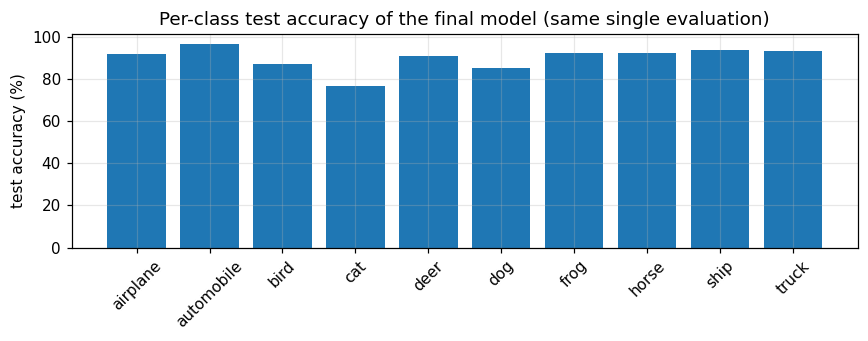

In [42]:
tv_test = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)
Xte = ((torch.from_numpy(tv_test.data).permute(0, 3, 1, 2).float().div(255) - mean) / std).to(device)
yte = torch.tensor(tv_test.targets).to(device)

_TEST_USED = False
@torch.no_grad()
def evaluate_on_test_once(model):
    global _TEST_USED
    assert not _TEST_USED, 'The test set has already been used once - it must not be used again!'
    _TEST_USED = True
    model.eval()
    return torch.cat([model(Xte[i:i+1000]).argmax(1) for i in range(0, len(Xte), 1000)])

preds = evaluate_on_test_once(final_model)
test_acc = (preds == yte).float().mean().item()
print(f'FINAL MODEL: {count_params(final_model):,} parameters, {EPOCHS_4} epochs')
print(f'validation accuracy: {abl["full recipe (final model)"]["val_acc"][-1]*100:.2f} %')
print(f'TEST accuracy (evaluated once): {test_acc*100:.2f} %')

per_class = [(preds[yte == c] == c).float().mean().item() for c in range(10)]
plt.figure(figsize=(8, 3.2)); plt.bar(CLASSES, np.array(per_class) * 100); plt.xticks(rotation=45); plt.ylabel('test accuracy (%)')
plt.title('Per-class test accuracy of the final model (same single evaluation)'); plt.tight_layout(); plt.show()

**Interpretation (4, test result).** The final model (420,670 parameters, 20 epochs) reaches 90.07% test accuracy, almost identical to its 90.00% validation accuracy, so tuning on the validation split did not overfit it. The hardest class is cat (about 77%), followed by dog (about 85%) and bird (about 87%). These animal classes look alike at 32x32 resolution, and cats are often confused with dogs. Automobile (about 97%), ship (about 94%) and truck (about 93%) are easiest because they have distinctive shapes and colours.

**Summary.** (1) I implemented Linear, ReLU, sigmoid and softmax cross-entropy with manual backprop. Gradient checks against autograd (~1e-12) and finite differences (~1e-7) passed, and a 10-layer sigmoid network showed vanishing gradients (layer-1 norm ~1e-5 vs ~1 at the output) while ReLU + Kaiming kept gradients stable. (2) My own SGD-momentum and Adam match PyTorch to ~1e-14. On an ill-conditioned quadratic, SGD was stable but slow, momentum was faster but oscillated, and Adam reached the lowest value. In the CNN sweep, momentum SGD (73.2%) and Adam (72.3%) performed best, and momentum SGD collapsed at lr 0.1. (3) On 5k images, flip+crop was the best single regulariser (73.4% vs 64.3% baseline), while combining everything under-fitted in 60 epochs. Residual connections fixed the degradation problem: plain-56 reached only 58.6% validation accuracy while residual-56 reached 87.9% with the same parameters. (4) A 0.42M-parameter ResNet-20 trained for 20 epochs reached 90.07% test accuracy, and augmentation and shortcuts were the most important design choices in the ablation.

**Acknowledgement and references.** I used Claude (Anthropic) to help generate the initial code structure and interpretation drafts, and I ran and checked all experiments myself. References: K. He et al., Deep Residual Learning for Image Recognition, CVPR 2016; D. Kingma and J. Ba, Adam, ICLR 2015; H. Zhang et al., mixup, ICLR 2018; T. DeVries and G. Taylor, Cutout, 2017; X. Glorot and Y. Bengio, AISTATS 2010; K. He et al., Delving Deep into Rectifiers, ICCV 2015.